# Per-Partition Composition

## Setup

In [11]:
from pathlib import Path
import sys, warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.decomposition import PCA
from sklearn.preprocessing import QuantileTransformer, StandardScaler

HERE = Path.cwd()
if str(HERE) not in sys.path:
    sys.path.insert(0, str(HERE))

from partitioning import _build_partitioner

warnings.filterwarnings('ignore')
np.random.seed(42)

METADATA_CSV = HERE / 'files' / 'train_N28.csv'
N_PARTITIONS = 20
SEED = 42
RANK_UTILIZATION = {
    'type': 'rank_utilization',
    'column': 'utilization',
    'keep_in_output': False,
    'levels': {'low': [0.70, 0.75], 'medium': [0.80], 'high': [0.85, 0.90]},
}

STRATEGIES = [
    {'name': 'feature_hierarchical', 'cfg': {'type': 'feature_hierarchical', 'n_partitions': N_PARTITIONS, 'features': ['design_name', 'utilization', 'clock'], 'preprocessing': [RANK_UTILIZATION], 'cluster_share': 0.8, 'dirichlet_alpha': 0.5, 'random_state': SEED}},
    {'name': 'kmeans', 'cfg': {'type': 'kmeans', 'n_partitions': N_PARTITIONS, 'cluster_share': 0.8, 'dirichlet_alpha': 0.5, 'random_state': SEED}},
]


## Load Metadata

In [12]:
df = pd.read_csv(METADATA_CSV)
META_COLS = [c for c in df.columns if c not in ('filename', 'sample_id')]

## Run Partitioners

In [13]:
def build_assignment(parts):
    assignment = np.full(len(df), -1, dtype=int)
    lookup = {name: i for i, name in enumerate(df['filename'].to_numpy())}
    for i, p in enumerate(parts):
        for name in p['filename']:
            assignment[lookup[name]] = i
    return assignment


results = {}
for entry in STRATEGIES:
    part = _build_partitioner(dict(entry['cfg']))
    parts = part.partition(df)
    results[entry['name']] = {
        'partitioner': part,
        'parts': parts,
        'assignment': build_assignment(parts),
        'sizes': [len(p) for p in parts],
    }

STRAT_NAMES = list(results)

## Per-Partition Composition

One column per partitioner (feature-hierarchical, then k-means), one row per
metadata factor (`design_name`, `clock`, `utilization`); one bar per
partition, stacked to 100 % by level.

Every bar is the same height, so a panel is read by **composition**:

- a bar filled with a single colour is a partition that is **pure** on that
  factor;
- a bar whose segments repeat the same proportions as its neighbours is a
  factor the partitioner **ignored**.

Each legend entry carries `σ`: the sample standard deviation (ddof = 1) of that
level's share across the partitions, in % points -- how much the level varies
from client to client (0 = identical in every client).

In [14]:
SEQ_CMAP = 'Blues'         
INK = '#2c3e50'

SERIES_COLORS = ['#2a78d6', '#eb6834', '#1baf7a', '#eda100',
                 '#e87ba4', '#008300', '#4a3aa7', '#e34948']
SERIES_INK = ['white', INK, INK, INK, INK, 'white', 'white', 'white']
COMPOSITION_RC = {
    'axes.grid': True, 'grid.color': 'white', 'grid.linewidth': 0.8,
    'axes.facecolor': '#f5f5f5', 'figure.facecolor': 'white',
}


def factor_levels(series):
    """Level labels of a factor, numerically ordered when possible."""
    vals = series.astype(str).unique()
    try:
        return sorted(vals, key=float)
    except ValueError:
        return sorted(vals)


def partition_profile(frame, labels, factor):
    """(count, percent-within-partition) for one factor; partitions are rows.

    Columns keep the factor's natural level order (numeric where the levels
    are numbers) rather than the lexicographic order `crosstab` would give,
    otherwise the bar positions stop carrying the ordering.
    """
    counts = pd.crosstab(pd.Series(labels, index=frame.index, name='partition'),
                         frame[factor].astype(str))
    counts = counts.reindex(columns=factor_levels(frame[factor]), fill_value=0)
    pct = (counts.div(counts.sum(axis=1), axis=0) * 100).round(2)
    return counts, pct


PLOT_STRATEGIES = ['feature_hierarchical', 'kmeans']
PLOT_FACTORS = ['design_name', 'clock', 'utilization']
STRATEGY_TITLES = {'feature_hierarchical': 'Feature-hierarchical', 'kmeans': 'K-means'}


def plot_composition_grid(frame, assignments, strategies, factors, label_min=8.0):
    """Grid of stacked-% bars: rows = factors, columns = strategies."""
    with plt.rc_context(COMPOSITION_RC):
        fig, axes = plt.subplots(len(factors), len(strategies),
                                 figsize=(7.6 * len(strategies), 3.2 * len(factors)),
                                 squeeze=False)
        for col, name in enumerate(strategies):
            labels = assignments[name]
            parts = sorted(pd.unique(labels))
            xs = np.arange(len(parts))
            for row, f in enumerate(factors):
                ax = axes[row, col]
                _, pct = partition_profile(frame, labels, f)
                pct = pct.reindex(parts)
                levels = list(pct.columns)
                bottom = np.zeros(len(parts))
                for i, level in enumerate(levels):
                    vals = pct[level].to_numpy(dtype=float)
                    ax.bar(xs, vals, bottom=bottom, width=0.62,
                           color=SERIES_COLORS[i], edgecolor='white',
                           linewidth=1.4, label=f'{level} (σ={vals.std(ddof=1):.1f})')
                    if len(levels) <= 4:
                        for x, value, base in zip(xs, vals, bottom):
                            if value >= label_min:
                                ax.text(x, base + value / 2, f'{value:.0f}',
                                        ha='center', va='center', fontsize=7,
                                        color=SERIES_INK[i])
                    bottom += vals
                ax.set_xticks(xs)
                ax.set_xticklabels([f'P{c}' for c in parts], fontsize=8)
                ax.set_xlabel('partition', fontsize=8)
                ax.set_ylabel('% within partition', fontsize=8)
                ax.set_ylim(0, 100)
                ax.set_yticks([0, 25, 50, 75, 100])
                ax.set_title(f'{STRATEGY_TITLES.get(name, name)} — {f}   ({len(levels)} levels)',
                             fontsize=9, loc='left')
                ax.legend(fontsize=7, ncol=min(len(levels), 8), frameon=False,
                          loc='lower right', bbox_to_anchor=(1.0, 1.0),
                          handlelength=0.9, handletextpad=0.4, columnspacing=0.8)
                ax.set_axisbelow(True)
                ax.xaxis.grid(False)
                ax.tick_params(labelsize=8, length=0)
        fig.suptitle(f'Factor level frequency per partition (K = {N_PARTITIONS})', y=1.005)
        plt.tight_layout(h_pad=2.4); plt.show()


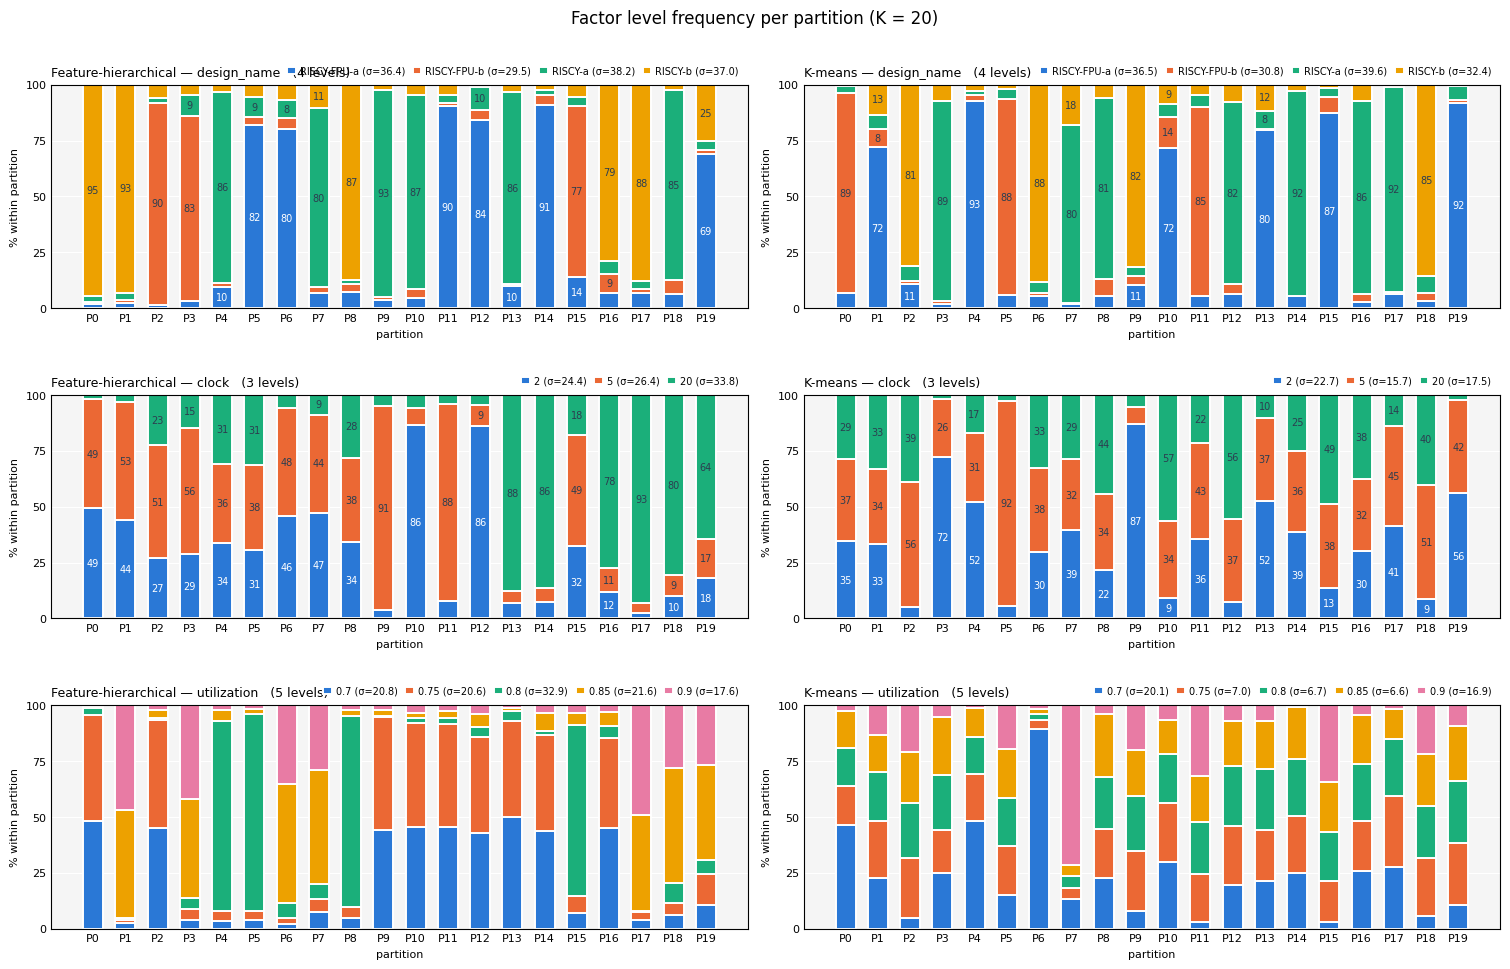

In [15]:
plot_composition_grid(
    df, {n: results[n]['assignment'] for n in PLOT_STRATEGIES},
    PLOT_STRATEGIES, PLOT_FACTORS)

## Variation Across Clients

σ of each level's share across the partitions (% points), as printed in the legends above.

In [19]:
def level_sigma_table(frame, assignments, strategies, factors):
    """σ of each level's share (% points) across partitions: rows = factor/level, cols = strategy."""
    cols = {}
    for name in strategies:
        labels = assignments[name]
        parts = sorted(pd.unique(labels))
        series = {}
        for f in factors:
            _, pct = partition_profile(frame, labels, f)
            sigma = pct.reindex(parts).std(ddof=1)
            for level, value in sigma.items():
                series[(f, level)] = value
        cols[STRATEGY_TITLES.get(name, name)] = pd.Series(series)
    table = pd.DataFrame(cols)
    table.index = pd.MultiIndex.from_tuples(table.index, names=['factor', 'level'])

    # mean σ over a factor's levels, appended after its rows; overall mean last
    blocks = []
    for f in factors:
        block = table.loc[[f]]
        mean_row = pd.DataFrame([block.mean()], index=pd.MultiIndex.from_tuples(
            [(f, 'mean σ')], names=table.index.names))
        blocks += [block, mean_row]
    return pd.concat(blocks).round(2)


level_sigma_table(df, {n: results[n]['assignment'] for n in PLOT_STRATEGIES},
                  PLOT_STRATEGIES, PLOT_FACTORS)

Feature-hierarchical  K-means
factor      level                                     
design_name RISCY-FPU-a                 36.36    36.52
            RISCY-FPU-b                 29.49    30.80
            RISCY-a                     38.19    39.65
            RISCY-b                     37.04    32.39
            mean σ                      35.27    34.84
clock       2                           24.38    22.66
            5                           26.40    15.73
            20                          33.81    17.55
            mean σ                      28.20    18.65
utilization 0.7                         20.80    20.07
            0.75                        20.62     6.98
            0.8                         32.90     6.67
            0.85                        21.61     6.60
            0.9                         17.60    16.94
            mean σ                      22.70    11.45